# 26 Nov

## Raw Data

PMT - 0.44-0.45
TA Current: 1 A
Cell temp: 120 .94 C (in loop)

LCVR

Temp - 40 C

	1. 1.26 V - 24.45 +/- 0.1
	2. 1.135 V - 21.7 +/- 0.17
	3. 1.12 V - 21.5 +/- 0.1
	4. 1.35 - 26.2 +/- 0.145 mw
	5. 1.45 V - 28.6 +/- 0.700

Frequency slope = -3234.446 ± 90.969 Hz/mW
Fractional coefficient K_P = -8.394994e-12 ± 2.361090e-13 per mW
Fractional coefficient K_P = -8.394994e-09 ± 2.361090e-10 per W
Chi-squared = 6.170
Degrees of freedom = 3
Reduced chi-squared = 2.057

At P0 = 24.45 mW:
  K_P P0 = -2.052576e-10 ± 5.772864e-12


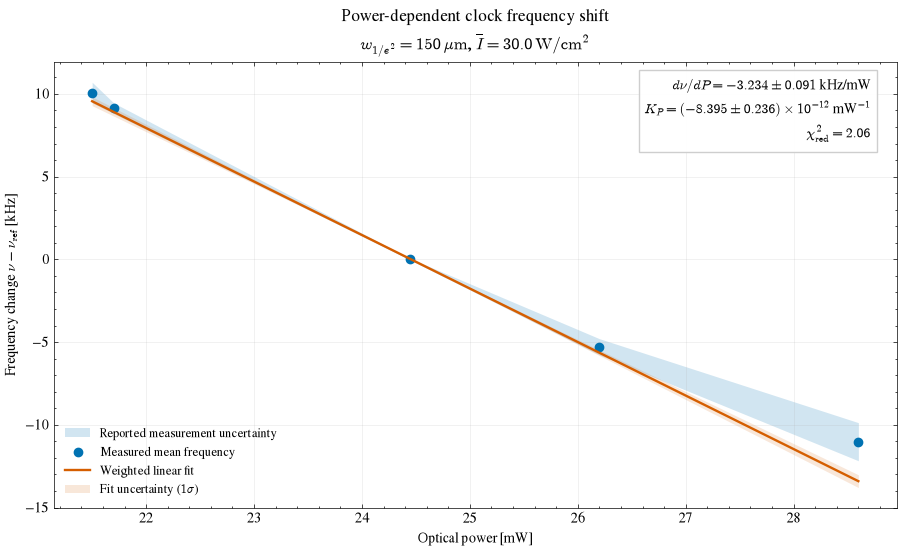

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
import scienceplots 
plt.style.use(["science", "no-latex"])
# Columns: optical power [mW], mean frequency [Hz], frequency error [Hz].
data = np.array([
    [24.45, 385282661486234.00,   47.9520744],
    [21.70, 385282661495370.00,  320.473936],
    [21.50, 385282661496320.00,  618.900749],
    [26.20, 385282661480952.00,  489.203695],
    [28.60, 385282661475213.00, 1152.37681],
], dtype=np.float64)

power_mw, frequency_hz, frequency_error_hz = data.T

# Fixed offsets improve numerical conditioning.
reference_frequency_hz = 385282661486234.00
reference_power_mw = 24.45

frequency_change_hz = frequency_hz - reference_frequency_hz


def linear_model(power, slope, offset):
    """Frequency change [Hz] versus optical power [mW]."""
    return slope * (power - reference_power_mw) + offset


# Treat the supplied errors as independent 1-sigma uncertainties.
parameters, covariance = curve_fit(
    linear_model,
    power_mw,
    frequency_change_hz,
    sigma=frequency_error_hz,
    absolute_sigma=True,
    p0=(-3200.0, 0.0),
)

slope_hz_per_mw, offset_hz = parameters
slope_error_hz_per_mw, offset_error_hz = np.sqrt(np.diag(covariance))

# Fractional-frequency sensitivity per unit ABSOLUTE optical power.
k_fractional_per_mw = slope_hz_per_mw / reference_frequency_hz
k_error_per_mw = slope_error_hz_per_mw / reference_frequency_hz

# Fit diagnostics.
residuals_hz = frequency_change_hz - linear_model(power_mw, *parameters)
chi_squared = np.sum((residuals_hz / frequency_error_hz)**2)
degrees_of_freedom = len(power_mw) - len(parameters)
reduced_chi_squared = chi_squared / degrees_of_freedom

print(
    f"Frequency slope = {slope_hz_per_mw:.3f} "
    f"± {slope_error_hz_per_mw:.3f} Hz/mW"
)
print(
    f"Fractional coefficient K_P = {k_fractional_per_mw:.6e} "
    f"± {k_error_per_mw:.6e} per mW"
)
print(
    f"Fractional coefficient K_P = {k_fractional_per_mw * 1e3:.6e} "
    f"± {k_error_per_mw * 1e3:.6e} per W"
)
print(f"Chi-squared = {chi_squared:.3f}")
print(f"Degrees of freedom = {degrees_of_freedom}")
print(f"Reduced chi-squared = {reduced_chi_squared:.3f}")

# For the earlier ADEV calculation:
# delta_nu / nu = (K_P * P0) * (delta_P / P0).
P0_mw = 24.45  # Set to the mean cell power of the relevant ADEV recording.
kp_p0 = k_fractional_per_mw * P0_mw
kp_p0_error = k_error_per_mw * P0_mw  # Excludes uncertainty in P0.

print(
    f"\nAt P0 = {P0_mw:g} mW:"
    f"\n  K_P P0 = {kp_p0:.6e} ± {kp_p0_error:.6e}"
)


# ============================================================
# PLOT
# ============================================================

order = np.argsort(power_mw)
power_sorted = power_mw[order]
change_sorted_khz = frequency_change_hz[order] / 1e3
error_sorted_khz = frequency_error_hz[order] / 1e3

power_fit = np.linspace(power_sorted.min(), power_sorted.max(), 400)
frequency_fit_hz = linear_model(power_fit, *parameters)

# Propagate the slope–offset covariance to the fitted mean line.
dx = power_fit - reference_power_mw
fit_variance_hz2 = (
    covariance[0, 0] * dx**2
    + 2 * covariance[0, 1] * dx
    + covariance[1, 1]
)
fit_error_hz = np.sqrt(np.maximum(fit_variance_hz2, 0))

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")

if hasattr(fig.canvas, "header_visible"):
    fig.canvas.header_visible = False

# Supplied measurement uncertainties.
ax.fill_between(
    power_sorted,
    change_sorted_khz - error_sorted_khz,
    change_sorted_khz + error_sorted_khz,
    color="#0072B2",
    alpha=0.18,
    linewidth=0,
    label="Reported measurement uncertainty",
)

ax.plot(
    power_sorted,
    change_sorted_khz,
    color="#0072B2",
    marker="o",
    linestyle="none",
    markersize=6,
    label="Measured mean frequency",
)

# Weighted straight-line fit.
ax.plot(
    power_fit,
    frequency_fit_hz / 1e3,
    color="#D55E00",
    linewidth=1.7,
    label="Weighted linear fit",
)

# Uncertainty of the fitted mean, not a prediction interval.
ax.fill_between(
    power_fit,
    (frequency_fit_hz - fit_error_hz) / 1e3,
    (frequency_fit_hz + fit_error_hz) / 1e3,
    color="#D55E00",
    alpha=0.15,
    linewidth=0,
    label=r"Fit uncertainty ($1\sigma$)",
)

annotation = (
    rf"$d\nu/dP = {slope_hz_per_mw / 1e3:.3f}"
    rf"\pm {slope_error_hz_per_mw / 1e3:.3f}$ kHz/mW"
    "\n"
    rf"$K_P = ({k_fractional_per_mw / 1e-12:.3f}"
    rf"\pm {k_error_per_mw / 1e-12:.3f})"
    rf"\times10^{{-12}}$ mW$^{{-1}}$"
    "\n"
    rf"$\chi^2_\mathrm{{red}}={reduced_chi_squared:.2f}$"
)

ax.text(
    0.97,
    0.97,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="0.8", alpha=0.95),
)

beam_radius_um = 150.0
beam_radius_m = beam_radius_um * 1e-6
mean_power_w = np.mean(power_mw) * 1e-3

# Spatial average inside the Gaussian beam's 1/e² radius,
# evaluated at the mean power of the measurements.
average_intensity_w_cm2 = (
    mean_power_w * (1 - np.exp(-2))
    / (np.pi * beam_radius_m**2)
    / 1e4
)

ax.set(
    title=(
        "Power-dependent clock frequency shift\n"
        rf"$w_{{1/e^2}}={beam_radius_um:g}\,\mu\mathrm{{m}}$, "
        rf"$\overline{{I}}={average_intensity_w_cm2:.1f}"
        rf"\,\mathrm{{W/cm^2}}$"
    ),
    xlabel="Optical power [mW]",
    ylabel=r"Frequency change $\nu-\nu_{\mathrm{ref}}$ [kHz]",
)

ax.grid(True, alpha=0.25)
ax.legend(loc="lower left", fontsize=9)

plt.show()


Intensity slope = -264.414 ± 7.437 Hz/(mW/mm²)
Fractional coefficient K_I = -6.862858e-13 ± 1.930177e-14 (mW/mm²)^-1


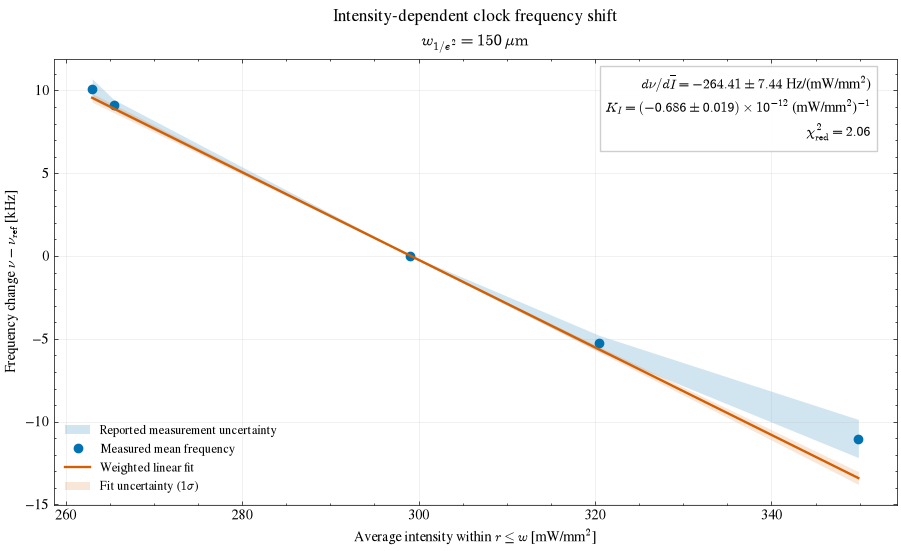

In [7]:
# ============================================================
# INTENSITY CONVERSION: mW/mm²
# ============================================================

beam_radius_um = 150.0
beam_radius_mm = beam_radius_um * 1e-3

# Average intensity inside r <= w for a Gaussian beam.
# Units: (mW/mm²) per mW = mm^-2.
intensity_per_mw = (
    (1 - np.exp(-2)) / (np.pi * beam_radius_mm**2)
)

intensity_mw_mm2 = power_mw * intensity_per_mw

# Convert the power slope into an intensity slope.
# Units: Hz / (mW/mm²).
slope_intensity = slope_hz_per_mw / intensity_per_mw
slope_intensity_error = slope_error_hz_per_mw / intensity_per_mw

# Fractional-frequency coefficient.
# Units: (mW/mm²)^-1 = mm²/mW.
k_intensity = k_fractional_per_mw / intensity_per_mw
k_intensity_error = k_error_per_mw / intensity_per_mw

print(
    f"\nIntensity slope = {slope_intensity:.3f} "
    f"± {slope_intensity_error:.3f} Hz/(mW/mm²)"
)
print(
    f"Fractional coefficient K_I = {k_intensity:.6e} "
    f"± {k_intensity_error:.6e} (mW/mm²)^-1"
)

# ============================================================
# PLOT
# ============================================================

order = np.argsort(intensity_mw_mm2)
intensity_sorted = intensity_mw_mm2[order]
change_sorted_khz = frequency_change_hz[order] / 1e3
error_sorted_khz = frequency_error_hz[order] / 1e3

power_fit = np.linspace(power_mw.min(), power_mw.max(), 400)
intensity_fit = power_fit * intensity_per_mw
frequency_fit_hz = linear_model(power_fit, *parameters)

# Uncertainty of the fitted mean, including covariance.
dx = power_fit - reference_power_mw
fit_variance_hz2 = (
    covariance[0, 0] * dx**2
    + 2 * covariance[0, 1] * dx
    + covariance[1, 1]
)
fit_error_hz = np.sqrt(np.maximum(fit_variance_hz2, 0))

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")

if hasattr(fig.canvas, "header_visible"):
    fig.canvas.header_visible = False

ax.fill_between(
    intensity_sorted,
    change_sorted_khz - error_sorted_khz,
    change_sorted_khz + error_sorted_khz,
    color="#0072B2",
    alpha=0.18,
    linewidth=0,
    label="Reported measurement uncertainty",
)

ax.plot(
    intensity_sorted,
    change_sorted_khz,
    color="#0072B2",
    marker="o",
    linestyle="none",
    markersize=6,
    label="Measured mean frequency",
)

ax.plot(
    intensity_fit,
    frequency_fit_hz / 1e3,
    color="#D55E00",
    linewidth=1.7,
    label="Weighted linear fit",
)

ax.fill_between(
    intensity_fit,
    (frequency_fit_hz - fit_error_hz) / 1e3,
    (frequency_fit_hz + fit_error_hz) / 1e3,
    color="#D55E00",
    alpha=0.15,
    linewidth=0,
    label=r"Fit uncertainty ($1\sigma$)",
)

annotation = (
    rf"$d\nu/d\overline{{I}} = {slope_intensity:.2f}"
    rf"\pm {slope_intensity_error:.2f}$"
    r" Hz/(mW/mm$^2$)"
    "\n"
    rf"$K_I = ({k_intensity / 1e-12:.3f}"
    rf"\pm {k_intensity_error / 1e-12:.3f})"
    r"\times10^{-12}$ (mW/mm$^2$)$^{-1}$"
    "\n"
    rf"$\chi^2_\mathrm{{red}}={reduced_chi_squared:.2f}$"
)

ax.text(
    0.97, 0.97,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="0.8", alpha=0.95),
)

ax.set(
    title=(
        "Intensity-dependent clock frequency shift\n"
        rf"$w_{{1/e^2}}={beam_radius_um:g}\,\mu\mathrm{{m}}$"
    ),
    xlabel=r"Average intensity within $r\leq w$ [mW/mm$^2$]",
    ylabel=r"Frequency change $\nu-\nu_{\mathrm{ref}}$ [kHz]",
)

ax.grid(True, alpha=0.25)
ax.legend(loc="lower left", fontsize=9)

plt.show()

# Light Shift Comparison with literature

The literature conversion is conditional on the beam model. Forward and return beams are assumed to be equal, overlapping Gaussians with constant radius over the detected vapor. Your power is assumed to be one-way power at the atoms.

In [12]:
%matplotlib inline

Text(0.04, 0.115, 'Literature conversion assumes equal, overlapping counterpropagating Gaussian beams.\nOur uncertainty includes the frequency fit only; beam size and power calibration are omitted.\nCommon convention: forward-beam area average inside the 1/e² radius \nI am assuming that the power used in the calculation is the forward power at the atoms, with equal overlapping beams and negligible waist variation along the detected region.')

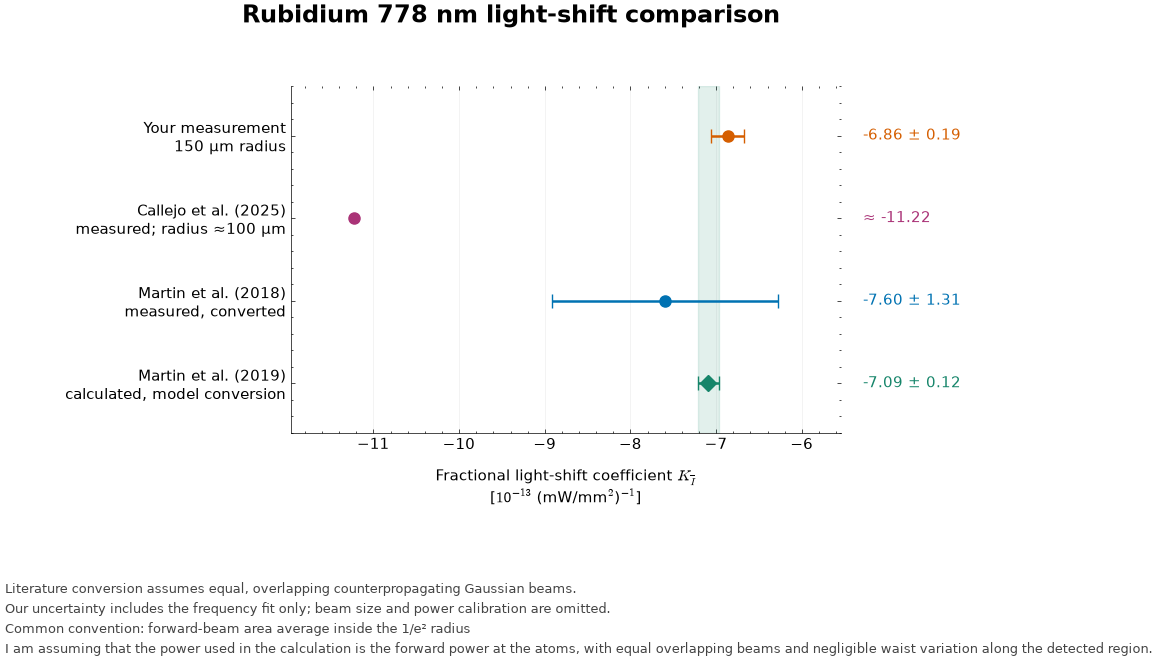

In [28]:
from pathlib import Path
import scienceplots 
plt.style.use(["science", "no-latex"])
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

OUT = Path.cwd()

# P is assumed to be ONE-WAY power at the vapor, in mW.
DATA = np.array([
    [24.45, 385282661486234.00, 47.9520744],
    [21.70, 385282661495370.00, 320.473936],
    [21.50, 385282661496320.00, 618.900749],
    [26.20, 385282661480952.00, 489.203695],
    [28.60, 385282661475213.00, 1152.37681],
])
BEAM_RADIUS_MM = 0.150
BEAM_RADIUS_ERROR_MM = 0.0  # Unknown: zero means OMITTED, not measured as zero.

# Both beam powers scale together. Equal radii, ideal overlap, constant radius
# along the detected cell length, weak excitation and uniform collection.
RETURN_TO_FORWARD_POWER = 1.0


p, nu, sigma_nu = DATA.T
nu_ref = nu[0]

def model(power, slope, offset):
    return slope * (power - p[0]) + offset

params, covariance = curve_fit(
    model, p, nu - nu_ref, sigma=sigma_nu,
    absolute_sigma=True, p0=(-3200.0, 0.0),
)
slope, offset = params
slope_error = np.sqrt(covariance[0, 0])
reduced_chi2 = np.sum(((nu - nu_ref - model(p, *params))/sigma_nu)**2)/(len(p)-2)


R = RETURN_TO_FORWARD_POWER
beam_area_mm2 = np.pi * BEAM_RADIUS_MM**2

# Each factor converts forward power [mW] to intensity [mW/mm²].
area_average_per_power = (1 - np.exp(-2)) / beam_area_mm2
forward_peak_per_power = 2 / beam_area_mm2
total_peak_per_power = (1 + R) * forward_peak_per_power
effective_per_power = (2 / 3) * total_peak_per_power

# Fractional sensitivity per unit of each intensity definition.
k_area = slope / nu_ref / area_average_per_power
k_forward_peak = slope / nu_ref / forward_peak_per_power
k_total_peak = slope / nu_ref / total_peak_per_power
k_effective = slope / nu_ref / effective_per_power

geometry_factor = effective_per_power / area_average_per_power

# Area average of FORWARD beam, restricted to r <= w:
# I_area = P (1-exp(-2))/(pi w^2), in mW/mm^2.
area_per_power = (1 - np.exp(-2))/(np.pi * BEAM_RADIUS_MM**2)
k_user_area = slope / nu_ref / area_per_power
k_user_area_error = abs(k_user_area) * np.hypot(
    slope_error / abs(slope), 2 * BEAM_RADIUS_ERROR_MM / BEAM_RADIUS_MM,
)

# From Martin 2019, Eqs. (5)-(6): signal weight is I_forward*I_return.
# Gaussian integrals give
# <I_total>_signal = 4(1+R) P / (3 pi w^2).
# Thus <I_total>_signal / I_area = 4(1+R)/[3(1-exp(-2))].
geometry_factor = 4 * (1 + RETURN_TO_FORWARD_POWER)/(3 * (1 - np.exp(-2)))


# Martin 2018: measured fractional power coefficient, section III A.
# Text reports 4.8(4)e-13/mW; the figure's fit-only error is 0.3e-13/mW.
# Use the text's 0.4e-13 and include their 0.66(5) mm radius uncertainty.
martin_2018_kp = -4.8e-13
martin_2018_kp_error = 0.4e-13
martin_2018_w = 0.66
martin_2018_w_error = 0.05
martin_2018_area_per_power = (1 - np.exp(-2))/(np.pi * martin_2018_w**2)
martin_2018_area = martin_2018_kp/martin_2018_area_per_power
martin_2018_error = abs(martin_2018_area) * np.hypot(
    martin_2018_kp_error/abs(martin_2018_kp),
    2*martin_2018_w_error/martin_2018_w,
)

# Martin 2019: reported atomic/intensity benchmarks. Convert to the present
# FORWARD beam area-average convention using the stated ideal Gaussian model.
# Do not insert the raw published numbers beside the user's area-average K.
martin_2019_measured = -2.5e-13 * geometry_factor
martin_2019_measured_error = 0.2e-13 * geometry_factor
martin_2019_theory = -2.30e-13 * geometry_factor
martin_2019_theory_error = 0.04e-13 * geometry_factor


# ============================================================
# ADD CALLEJO ET AL.
# ============================================================

callejo_slope_hz_per_mw = -11.9e3
callejo_radius_mm = 0.100  # Approximate reported waist radius.

# Convert their measured power sensitivity directly into OUR
# forward-beam area-average intensity convention.
# No 3.084 geometry factor is needed for this conversion.
callejo_area_per_power = (
    (1 - np.exp(-2))
    / (np.pi * callejo_radius_mm**2)
)

callejo_k_area = (
    callejo_slope_hz_per_mw
    / nu_ref
    / callejo_area_per_power
)

# ============================================================
# COMPARISON PLOT
# ============================================================

labels = [
    "Your measurement\n150 µm radius",
    "Callejo et al. (2025)\nmeasured; radius ≈100 µm",
    "Martin et al. (2018)\nmeasured, converted",
    "Martin et al. (2019)\ncalculated, model conversion",
]

values = np.array([
    k_user_area,
    callejo_k_area,
    martin_2018_area,
    martin_2019_theory,
])

errors = np.array([
    k_user_area_error,
    np.nan,  # Complete uncertainty unavailable.
    martin_2018_error,
    martin_2019_theory_error,
])

colors = ["#D55E00", "#AA3377", "#0072B2", "#16856A"]
scale = 1e-13

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6.8))
fig.subplots_adjust(
    left=0.30, right=0.80,
    bottom=0.33, top=0.84,
)

# Conditional theoretical prediction and its reported uncertainty.
ax.axvspan(
    (martin_2019_theory - martin_2019_theory_error) / scale,
    (martin_2019_theory + martin_2019_theory_error) / scale,
    color=colors[-1],
    alpha=0.12,
)

for y, (value, error, color) in enumerate(
    zip(values, errors, colors)
):
    marker = "D" if y == 3 else "o"

    if np.isfinite(error):
        ax.errorbar(
            value / scale,
            y,
            xerr=error / scale,
            fmt=marker,
            color=color,
            markersize=8,
            capsize=5,
            elinewidth=1.8,
            zorder=3,
        )
        value_text = f"{value / scale:.2f} ± {error / scale:.2f}"

    else:
        ax.plot(
            value / scale,
            y,
            marker=marker,
            linestyle="none",
            color=color,
            markersize=8,
            zorder=3,
        )
        value_text = f"≈ {value / scale:.2f}"

    # Place numerical results outside the plotting area.
    ax.text(
        1.04, y,
        value_text,
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="center",
        color=color,
        fontsize=11,
        clip_on=False,
    )

ax.set_yticks(np.arange(len(labels)), labels)
ax.set_ylim(len(labels) - 0.4, -0.6)

# Automatically accommodate all values and uncertainty bars.
finite_errors = np.nan_to_num(errors, nan=0.0)
lower = np.min((values - finite_errors) / scale)
upper = np.max((values + finite_errors) / scale)
padding = 0.15 * (upper - lower)
ax.set_xlim(lower - padding, upper + padding)

ax.set_xlabel(
    r"Fractional light-shift coefficient $K_{\overline{I}}$"
    "\n"
    r"[$10^{-13}$ (mW/mm$^2$)$^{-1}$]",
    labelpad=10,
)

ax.grid(axis="x", alpha=0.20)
ax.set_axisbelow(True)

fig.suptitle(
    "Rubidium 778 nm light-shift comparison",
    fontsize=17,
    fontweight="bold",
    y=0.96,
)


fig.text(0.04, 0.115,
         "Literature conversion assumes equal, overlapping counterpropagating Gaussian beams.\n"
         "Our uncertainty includes the frequency fit only; beam size and power calibration are omitted.\n"
         "Common convention: forward-beam area average inside the 1/e² radius \n"
        "I am assuming that the power used in the calculation is the forward power at the atoms, with equal overlapping beams and negligible waist variation along the detected region."
        ,
         va="top", fontsize=9, color="#444444", linespacing=1.6)



K. W. Martin et al., Compact Optical Atomic Clock Based on a Two-Photon
Transition in Rubidium, Physical Review Applied 9, 014019 (2018).
DOI: https://doi.org/10.1103/PhysRevApplied.9.014019



K. W. Martin et al., Frequency shifts due to Stark effects on a rubidium
two-photon transition, Physical Review A 100, 023417 (2019).
DOI: https://doi.org/10.1103/PhysRevA.100.023417
